In [2]:
# ==========================================
# CELL 1: IMPORT THƯ VIỆN & CẤU HÌNH TRỰC QUAN HÓA
# ==========================================
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc,
    f1_score, precision_score, recall_score, roc_auc_score
)

# Thử import lightgbm, nếu chưa có thì dùng HistGradientBoostingClassifier tương đương
try:
    import lightgbm as lgb
    HAS_LIGHTGBM = True
    print("[+] LightGBM đã được cài đặt sẵn.")
except ImportError:
    HAS_LIGHTGBM = False
    print("[!] Không tìm thấy LightGBM, sử dụng HistGradientBoostingClassifier (tương đương).")

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

[+] LightGBM đã được cài đặt sẵn.


In [3]:
# ==========================================
# CELL 2: TẢI DATASET & ĐỌC METADATA
# ==========================================
# Kiểm tra các đường dẫn mặc định trên Kaggle
POSSIBLE_PATHS = [
    "/kaggle/input/smoke-detection-dataset/smoke_detection_iot.csv",
    "/kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv",
    "smoke_detection_iot.csv"
]

dataset_path = None
for path in POSSIBLE_PATHS:
    if os.path.exists(path):
        dataset_path = path
        break

if dataset_path is None:
    raise FileNotFoundError("Không tìm thấy file smoke_detection_iot.csv. Vui lòng kiểm tra lại Input Data trên Kaggle.")

print(f"[*] Đang đọc dataset từ: {dataset_path}")
df_raw = pd.read_csv(dataset_path)

# Hiển thị thông tin tổng quan
print(f"[*] Kích thước bảng dữ liệu: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột")
print("\n--- 5 dòng đầu tiên ---")
display(df_raw.head())

print("\n--- Phân bố nhãn Fire Alarm (0: Safe, 1: Fire) ---")
print(df_raw['Fire Alarm'].value_counts())

[*] Đang đọc dataset từ: /kaggle/input/datasets/deepcontractor/smoke-detection-dataset/smoke_detection_iot.csv
[*] Kích thước bảng dữ liệu: 62630 dòng, 16 cột

--- 5 dòng đầu tiên ---


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0



--- Phân bố nhãn Fire Alarm (0: Safe, 1: Fire) ---
Fire Alarm
1    44757
0    17873
Name: count, dtype: int64


In [4]:
# ==========================================
# CELL 3: XỬ LÝ CHUỖI THỜI GIAN & CHIA TẬP TRAIN/VAL/TEST
# ==========================================
# 1. Sắp xếp chuỗi thời gian & phát hiện các phiên đo đứt đoạn (gián đoạn > 10s)
df_sorted = df_raw.sort_values(by=['UTC', 'CNT']).reset_index(drop=True)
df_sorted['exp_id'] = (df_sorted['UTC'].diff() > 10).cumsum()

print(f"[+] Phát hiện {df_sorted['exp_id'].nunique()} phiên đo thử nghiệm riêng biệt.")

# 2. Hàm trích xuất 16 đặc trưng động trên 4 cảm biến phần cứng (SHT31 & PMS5003)
def extract_session_features(group):
    f = pd.DataFrame(index=group.index)
    
    # 4 Đặc trưng thô
    f['temperature_c'] = group['Temperature[C]']
    f['humidity_pct'] = group['Humidity[%]']
    f['pm1_ug_m3'] = group['PM1.0']
    f['pm25_ug_m3'] = group['PM2.5']
    
    # Tỷ lệ biến thiên
    f['pm_ratio'] = (group['PM2.5'] + 1e-3) / (group['PM1.0'] + 1e-3)
    f['temp_hum_ratio'] = group['Temperature[C]'] / (group['Humidity[%]'] + 1e-3)
    
    # Tốc độ biến thiên (Biến thiên sau 5 mẫu ~ 5 giây)
    f['d_temp_5'] = group['Temperature[C]'].diff(5).fillna(0)
    f['d_hum_5'] = group['Humidity[%]'].diff(5).fillna(0)
    f['d_pm1_5'] = group['PM1.0'].diff(5).fillna(0)
    f['d_pm25_5'] = group['PM2.5'].diff(5).fillna(0)
    
    # Thống kê cửa sổ trượt W = 5
    f['temp_roll_5_mean'] = group['Temperature[C]'].rolling(5, min_periods=1).mean()
    f['hum_roll_5_mean'] = group['Humidity[%]'].rolling(5, min_periods=1).mean()
    f['pm1_roll_5_mean'] = group['PM1.0'].rolling(5, min_periods=1).mean()
    f['pm25_roll_5_mean'] = group['PM2.5'].rolling(5, min_periods=1).mean()
    f['temp_roll_5_std'] = group['Temperature[C]'].rolling(5, min_periods=1).std().fillna(0)
    f['hum_roll_5_std'] = group['Humidity[%]'].rolling(5, min_periods=1).std().fillna(0)
    
    return f

# 3. Chia tập theo phiên (60% Train, 20% Val, 20% Test) chống rò rỉ dữ liệu
train_list, val_list, test_list = [], [], []

for exp_id, group in df_sorted.groupby('exp_id'):
    n = len(group)
    n_train = int(n * 0.6)
    n_val = int(n * 0.2)
    
    train_list.append(group.iloc[:n_train])
    val_list.append(group.iloc[n_train:n_train+n_val])
    test_list.append(group.iloc[n_train+n_val:])

df_train = pd.concat(train_list).reset_index(drop=True)
df_val = pd.concat(val_list).reset_index(drop=True)
df_test = pd.concat(test_list).reset_index(drop=True)

def build_dataset(df_subset):
    feats = []
    for exp_id, group in df_subset.groupby('exp_id'):
        feats.append(extract_session_features(group))
    X = pd.concat(feats).reset_index(drop=True)
    y = df_subset['Fire Alarm'].reset_index(drop=True)
    return X, y

X_train, y_train = build_dataset(df_train)
X_val, y_val = build_dataset(df_val)
X_test, y_test = build_dataset(df_test)

print(f"[*] Train shape: {X_train.shape} | Val shape: {X_val.shape} | Test shape: {X_test.shape}")

[+] Phát hiện 5 phiên đo thử nghiệm riêng biệt.
[*] Train shape: (37576, 16) | Val shape: (12522, 16) | Test shape: (12532, 16)


In [5]:
# ==========================================
# CELL 4: HUẤN LUYỆN MÔ HÌNH SO SÁNH
# ==========================================

# 1. Baseline: Random Forest v1 (Chỉ dùng 4 biến thô tức thời)
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train[['temperature_c', 'humidity_pct', 'pm1_ug_m3', 'pm25_ug_m3']], y_train)
y_pred_base = rf_baseline.predict(X_test[['temperature_c', 'humidity_pct', 'pm1_ug_m3', 'pm25_ug_m3']])

# 2. Mô hình Đề xuất: LightGBM / HistGradientBoosting (16 biến động)
if HAS_LIGHTGBM:
    model_opt = lgb.LGBMClassifier(
        n_estimators=150, max_depth=6, num_leaves=31, learning_rate=0.05, random_state=42, n_jobs=-1
    )
else:
    model_opt = HistGradientBoostingClassifier(
        max_iter=150, max_depth=6, learning_rate=0.05, random_state=42
    )

model_opt.fit(X_train, y_train)
y_pred_opt = model_opt.predict(X_test)
y_prob_opt = model_opt.predict_proba(X_test)[:, 1]

# 3. Tổng hợp bảng chỉ số
metrics_data = {
    'Mô hình': ['Random Forest v1 (4 biến thô)', 'LightGBM / Boosting (16 biến động)'],
    'F1-Score': [f1_score(y_test, y_pred_base), f1_score(y_test, y_pred_opt)],
    'Precision': [precision_score(y_test, y_pred_base), precision_score(y_test, y_pred_opt)],
    'Recall': [recall_score(y_test, y_pred_base), recall_score(y_test, y_pred_opt)],
    'ROC AUC': [
        roc_auc_score(y_test, rf_baseline.predict_proba(X_test[['temperature_c', 'humidity_pct', 'pm1_ug_m3', 'pm25_ug_m3']])[:, 1]),
        roc_auc_score(y_test, y_prob_opt)
    ]
}
df_metrics = pd.DataFrame(metrics_data)
display(df_metrics.style.highlight_max(color='lightgreen', subset=['F1-Score', 'Precision', 'Recall', 'ROC AUC']))

[LightGBM] [Info] Number of positive: 24299, number of negative: 13277
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.007337 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4080
[LightGBM] [Info] Number of data points in the train set: 37576, number of used features: 16
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.646663 -> initscore=0.604402
[LightGBM] [Info] Start training from score 0.604402


,Mô hình,F1-Score,Precision,Recall,ROC AUC
0,Random Forest v1 (4 biến thô),0.879507,0.848284,0.913116,0.518358
1,LightGBM / Boosting (16 biến động),0.935516,0.896889,0.977619,0.782882


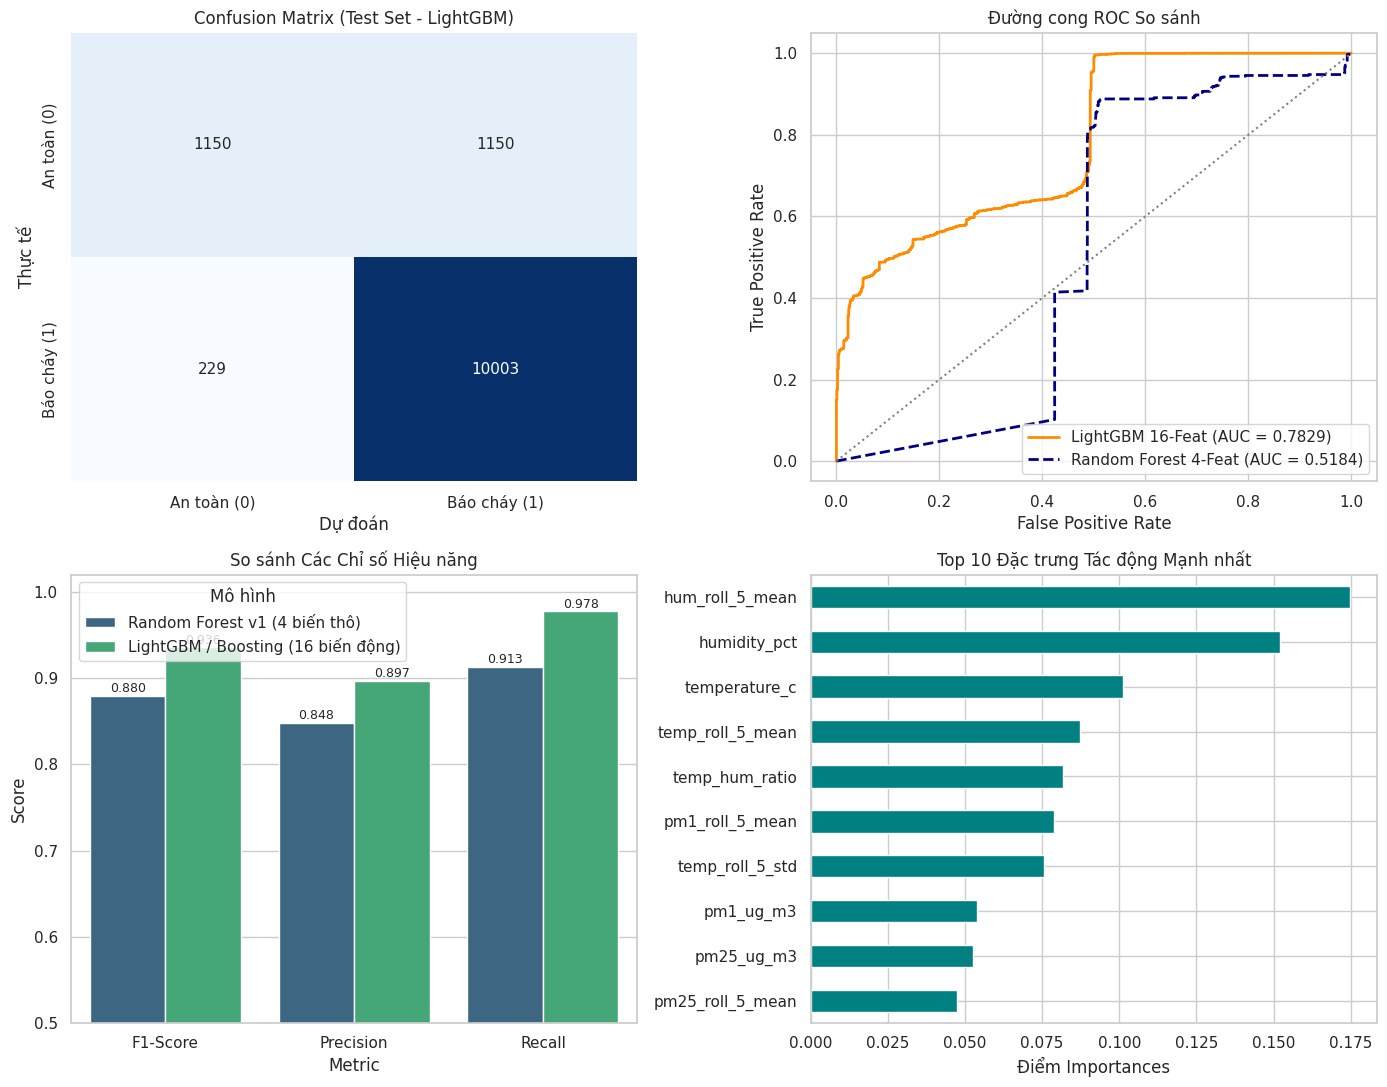

In [6]:
# ==========================================
# CELL 5: BIỂU ĐỒ TRỰC QUAN HÓA KẾT QUẢ
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# 1. Confusion Matrix (Tập Test)
cm = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0], cbar=False,
            xticklabels=['An toàn (0)', 'Báo cháy (1)'], yticklabels=['An toàn (0)', 'Báo cháy (1)'])
axes[0, 0].set_title('Confusion Matrix (Test Set - LightGBM)')
axes[0, 0].set_xlabel('Dự đoán')
axes[0, 0].set_ylabel('Thực tế')

# 2. Đô thị ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_opt)
fpr_b, tpr_b, _ = roc_curve(y_test, rf_baseline.predict_proba(X_test[['temperature_c', 'humidity_pct', 'pm1_ug_m3', 'pm25_ug_m3']])[:, 1])

axes[0, 1].plot(fpr, tpr, color='darkorange', lw=2, label=f'LightGBM 16-Feat (AUC = {auc(fpr, tpr):.4f})')
axes[0, 1].plot(fpr_b, tpr_b, color='navy', lw=2, linestyle='--', label=f'Random Forest 4-Feat (AUC = {auc(fpr_b, tpr_b):.4f})')
axes[0, 1].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[0, 1].set_xlabel('False Positive Rate')
axes[0, 1].set_ylabel('True Positive Rate')
axes[0, 1].set_title('Đường cong ROC So sánh')
axes[0, 1].legend(loc='lower right')

# 3. So sánh chỉ số F1, Precision, Recall
df_melt = pd.melt(df_metrics, id_vars=['Mô hình'], value_vars=['F1-Score', 'Precision', 'Recall'], var_name='Metric', value_name='Score')
sns.barplot(data=df_melt, x='Metric', y='Score', hue='Mô hình', ax=axes[1, 0], palette='viridis')
axes[1, 0].set_ylim(0.5, 1.02)
axes[1, 0].set_title('So sánh Các Chỉ số Hiệu năng')
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)

# 4. Độ quan trọng của Đặc trưng (Feature Importances)
rf_importance = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
imp_series = pd.Series(rf_importance.feature_importances_, index=X_train.columns).sort_values(ascending=True)

imp_series.tail(10).plot(kind='barh', ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Top 10 Đặc trưng Tác động Mạnh nhất')
axes[1, 1].set_xlabel('Điểm Importances')

plt.tight_layout()
plt.show()

In [7]:
# CELL 6: Chọn ngưỡng trên validation và đánh giá luật 3/5
WINDOW_SIZE = 5
REQUIRED_VOTES = 3
MAX_VAL_FPR = 0.10

thresholds = np.round(np.arange(0.50, 0.951, 0.05), 2)
positive_index = list(model_opt.classes_).index(1)


def vote_3_of_5(frame, scores, threshold):
    # Bắt đầu lại cửa sổ khi đổi phiên hoặc chuỗi mẫu bị gián đoạn.
    reset = (
        frame["exp_id"].ne(frame["exp_id"].shift())
        | frame["UTC"].diff().ne(1)
        | frame["CNT"].diff().ne(1)
    )
    block = reset.cumsum()

    flags = pd.Series(scores >= threshold, index=frame.index)
    votes = flags.groupby(block, sort=False).transform(
        lambda part: part.rolling(WINDOW_SIZE, min_periods=WINDOW_SIZE).sum()
    )
    return votes.ge(REQUIRED_VOTES).to_numpy()


def summarize_predictions(y_true, predictions):
    tn, fp, fn, tp = map(
        int, confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    )
    return {
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "fpr": fp / (fp + tn),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }


# Chỉ dùng validation để chọn ngưỡng.
val_scores = model_opt.predict_proba(X_val)[:, positive_index]
val_table = pd.DataFrame([
    {
        "threshold": float(threshold),
        **summarize_predictions(
            y_val, vote_3_of_5(df_val, val_scores, threshold)
        ),
    }
    for threshold in thresholds
])

eligible = val_table.loc[val_table["fpr"] <= MAX_VAL_FPR]
if eligible.empty:
    eligible = val_table.loc[val_table["fpr"] == val_table["fpr"].min()]
    print("Không có ngưỡng nào đạt mục tiêu báo nhầm trên validation.")

best = eligible.sort_values(
    ["recall", "f1", "fpr", "threshold"],
    ascending=[False, False, True, False],
).iloc[0]

T_HIGH = float(best["threshold"])
val_result = summarize_predictions(
    y_val, vote_3_of_5(df_val, val_scores, T_HIGH)
)

print(f"Ngưỡng chọn trên validation = {T_HIGH:.2f}")
display(val_table.round(4))

# Chấm test bằng ngưỡng đã chọn.
test_scores = model_opt.predict_proba(X_test)[:, positive_index]
test_direct = summarize_predictions(y_test, test_scores >= T_HIGH)
test_voting = summarize_predictions(
    y_test, vote_3_of_5(df_test, test_scores, T_HIGH)
)

test_table = pd.DataFrame(
    [test_direct, test_voting],
    index=["Báo ngay", "Xác nhận 3/5"],
)
display(test_table.round(4))

Không có ngưỡng nào đạt mục tiêu báo nhầm trên validation.
Ngưỡng chọn trên validation = 0.95


,threshold,recall,precision,f1,fpr,tp,fp,fn,tn
0,0.50,0.9956,0.9426,0.9684,0.2700,10181,620,45,1676
1,0.55,0.9956,0.9431,0.9687,0.2674,10181,614,45,1682
2,0.60,0.9955,0.9434,0.9687,0.2661,10180,611,46,1685
3,0.65,0.9942,0.9450,0.9690,0.2578,10167,592,59,1704
4,0.70,0.9912,0.9461,0.9681,0.2513,10136,577,90,1719
5,0.75,0.9886,0.9484,0.9681,0.2395,10109,550,117,1746
6,0.80,0.9839,0.9511,0.9672,0.2252,10061,517,165,1779
7,0.85,0.9807,0.9537,0.9670,0.2121,10029,487,197,1809
8,0.90,0.9697,0.9593,0.9645,0.1834,9916,421,310,1875
9,0.95,0.9491,0.9636,0.9563,0.1598,9706,367,520,1929


,recall,precision,f1,fpr,tp,fp,fn,tn
Báo ngay,0.8548,0.8852,0.8697,0.4930,8746,1134,1486,1166
Xác nhận 3/5,0.8572,0.8859,0.8713,0.4913,8771,1130,1461,1170


In [9]:
# CELL 7: Xuất model và metadata cho backend
from pathlib import Path

output_dir = Path("/kaggle/working/models")
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "lightgbm_smoke_model.joblib"
metadata_path = output_dir / "metadata.json"

metadata = {
    "model_name": type(model_opt).__name__,
    "num_features": len(X_train.columns),
    "features": list(X_train.columns),
    "positive_label": 1,
    "decision_policy": {
        "T_HIGH": T_HIGH,
        "window_size": WINDOW_SIZE,
        "required_votes": REQUIRED_VOTES,
        "require_full_window": True,
        "reset_on_session_or_sample_gap": True,
    },
    "validation": {
        "fpr_target": MAX_VAL_FPR,
        "target_met": val_result["fpr"] <= MAX_VAL_FPR,
        **val_result,
    },
    "test_within_session": {
        "direct": test_direct,
        "vote_3_of_5": test_voting,
    },
}

joblib.dump(model_opt, model_path)
metadata_path.write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

print(f"Model: {model_path}")
print(f"Metadata: {metadata_path}")
print(f"Ngưỡng đã lưu: {T_HIGH:.2f}")

Model: /kaggle/working/models/lightgbm_smoke_model.joblib
Metadata: /kaggle/working/models/metadata.json
Ngưỡng đã lưu: 0.95


In [10]:
# Tạo ZIP chứa model và metadata, rồi hiện link tải
from os.path import relpath
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

zip_path = output_dir.parent / "smoke_model_bundle.zip"

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as bundle:
    bundle.write(model_path, arcname="lightgbm_smoke_model.joblib")
    bundle.write(metadata_path, arcname="metadata.json")

display(FileLink(relpath(zip_path), result_html_prefix="Tải model và metadata: "))

/kaggle/working/smoke_model_bundle.zip